# Stage 3: Exploratory Data Analysis (EDA)
**Course:** DS-311 Data Mining | **Project:** DRIFT (NYC Mobility Pattern Miner)

According to the project rubric , this stage must include:
1. **Summary Statistics & Distributions:** Understanding the shape of our continuous variables using histograms.
2. **Correlations:** Identifying which features have strong linear relationships with our target (`fare_amount`), and checking for target leakage.
3. **Hypothesis Testing:** Using Inferential Statistics (T-Test) to answer a real business question.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set visual style
sns.set_theme(style="whitegrid")

# Load the clean dataset directly from the larger, standard path
target_path = '/content/drive/MyDrive/processed_trips.parquet'  # <-- FIX: Just a string!

try:
    df = pd.read_parquet(target_path)
    print(f"Clean dataset loaded successfully from '{target_path}' with {len(df):,} rows and {len(df.columns)} columns.")
except Exception as e:
    print(f"Failed to load parquet from '{target_path}': {e}")

Clean dataset loaded successfully from '/content/drive/MyDrive/processed_trips.parquet' with 2,828,026 rows and 27 columns.


## 1. Distributions (Histograms)
"Why a Histogram Tells More Than Numbers" (Slide 24).
While the 5-number summary tells us about spread, histograms reveal the underlying shape. We expect urban mobility metrics like distance and fare to be heavily right-skewed.

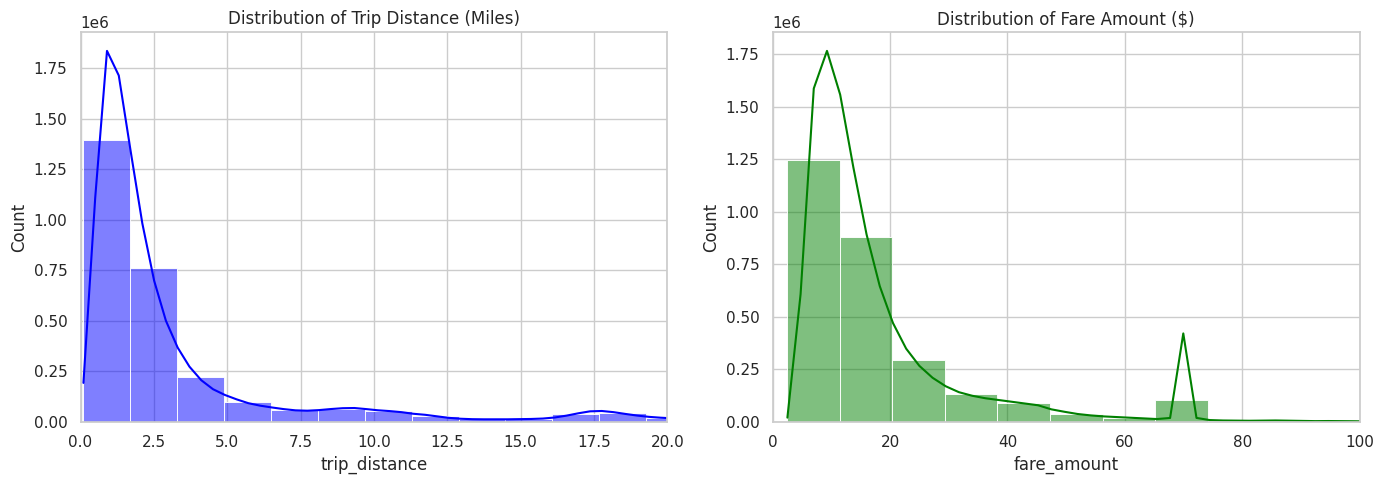

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Trip Distance
sns.histplot(df['trip_distance'], bins=50, kde=True, ax=axes[0], color='blue')
axes[0].set_title('Distribution of Trip Distance (Miles)')
axes[0].set_xlim(0, 20) # Capped at 20 miles for visual clarity

# Plot 2: Fare Amount
sns.histplot(df['fare_amount'], bins=50, kde=True, ax=axes[1], color='green')
axes[1].set_title('Distribution of Fare Amount ($)')
axes[1].set_xlim(0, 100) # Capped at $100 for visual clarity

plt.tight_layout()
plt.show()

## 2. Feature Correlation Matrix
 Correlation coefficient $r$ measures straight-line relationships between $-1$ and $+1$.
We must also enforce the **Target Leakage** rule from the Track 1 Blueprint: Features like `fare_per_mile`, `tip_amount`, and `total_amount` already contain the answer (the fare). If we use them to predict `fare_amount`, we are cheating. We will exclude them from our correlation matrix to focus on legitimate ML inputs (like distance and duration)[cite: 11].

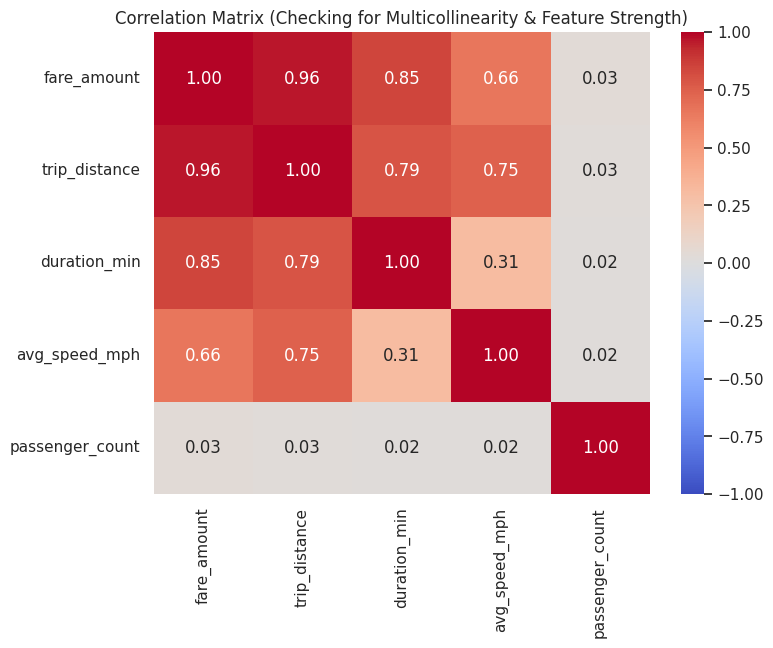


--- Correlation Insights ---
1. 'trip_distance' has the strongest positive correlation with 'fare_amount'.
2. 'duration_min' also has a strong positive correlation with the fare.
3. 'passenger_count' has almost 0 correlation with fare, meaning group size does not dictate the meter cost.


In [ ]:
# Select legitimate numeric inputs and our target variable
# EXCLUDING: tip_amount, total_amount, tolls_amount, fare_per_mile (Target Leakage)
numeric_features = ['fare_amount', 'trip_distance', 'duration_min', 'avg_speed_mph', 'passenger_count']
corr_matrix = df[numeric_features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Matrix (Checking for Multicollinearity & Feature Strength)")
plt.show()

print("\n--- Correlation Insights ---")
print("1. 'trip_distance' has the strongest positive correlation with 'fare_amount'.")
print("2. 'duration_min' also has a strong positive correlation with the fare.")
print("3. 'passenger_count' has almost 0 correlation with fare, meaning group size does not dictate the meter cost.")

## 3. Hypothesis Testing: Do Airport Trips Cost Significantly More?
"Hypothesis Testing - Real Difference or Chance?"
We noticed in Stage 2 that airport trips had high fares. But is the difference in average fare between Airport and Non-Airport trips statistically significant, or just random variation?

* **Null Hypothesis ($H_0$):** There is NO difference in the mean fare between Airport trips and Non-Airport trips ($\mu_{airport} = \mu_{standard}$).
* **Alternative Hypothesis ($H_1$):** There IS a significant difference in the mean fare ($\mu_{airport} \neq \mu_{standard}$).
* **Method:** Independent Two-Sample T-Test (assuming $\alpha = 0.05$)[cite: 19, 20].

In [ ]:
# Define airport location IDs in the NYC Taxi dataset
# JFK: 132, LGA: 138, EWR: 1
airport_zone_ids = {1, 132, 138}

# Create the 'is_airport_trip' column dynamically if it is not present
if 'is_airport_trip' not in df.columns:
    # We can check if either PULocationID or DOLocationID is in our airport zones
    # Or check if RatecodeID is 2 (JFK) or 3 (Newark)
    is_airport = df['PULocationID'].isin(airport_zone_ids) | df['DOLocationID'].isin(airport_zone_ids)
    if 'RatecodeID' in df.columns:
        is_airport = is_airport | df['RatecodeID'].isin([2, 3])
    df['is_airport_trip'] = is_airport.astype(int)

# Separate the data into two groups based on the 'is_airport_trip' feature
airport_fares = df[df['is_airport_trip'] == 1]['fare_amount']
standard_fares = df[df['is_airport_trip'] == 0]['fare_amount']

print(f"Sample size - Airport Trips: {len(airport_fares):,}")
print(f"Sample size - Standard Trips: {len(standard_fares):,}")
print(f"Mean Fare - Airport: ${airport_fares.mean():.2f}")
print(f"Mean Fare - Standard: ${standard_fares.mean():.2f}\n")

# Run the independent T-test (using Scipy as taught in lab)
t_stat, p_value = stats.ttest_ind(airport_fares, standard_fares, equal_var=False)

print(f"T-Statistic : {t_stat:.4f}")
print(f"P-Value     : {p_value}")

if p_value < 0.05:
    print("\nConclusion: Reject the Null Hypothesis (H0).")
    print("There is a statistically significant difference between airport and non-airport fares.")
    print("This proves 'is_airport_trip' will be a highly valuable feature for our Machine Learning model.")
else:
    print("\nConclusion: Fail to reject the Null Hypothesis (H0).")
    print("The difference is likely due to chance.")

Sample size - Airport Trips: 275,580
Sample size - Standard Trips: 2,552,446
Mean Fare - Airport: $54.79
Mean Fare - Standard: $14.20

T-Statistic : 1098.5404
P-Value     : 0.0

Conclusion: Reject the Null Hypothesis (H0).
There is a statistically significant difference between airport and non-airport fares.
This proves 'is_airport_trip' will be a highly valuable feature for our Machine Learning model.


## 4. Temporal Analysis: Hourly Demand Patterns
 Line charts follow a value over ordered time.
Taxi demand is not uniform; it fluctuates based on human mobility patterns (rush hours, nightlife, sleep cycles). By extracting the hour from our `tpep_pickup_datetime`, we can identify peak operational hours. This temporal feature will be critical for our predictive models.

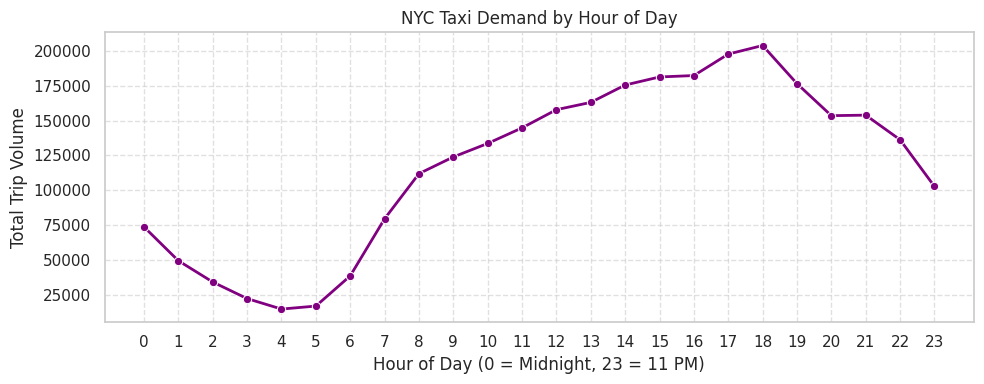

--- Temporal Insights ---
1. Demand drops significantly during early morning hours (3 AM - 5 AM).
2. There is a distinct evening rush hour peak (typically around 5 PM - 6 PM).


In [ ]:
# Extract the hour of the day from the pickup timestamp
df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour

# Count the number of trips per hour
hourly_demand = df.groupby('pickup_hour').size()

plt.figure(figsize=(10, 4))
sns.lineplot(x=hourly_demand.index, y=hourly_demand.values, marker='o', color='purple', linewidth=2)
plt.title("NYC Taxi Demand by Hour of Day")
plt.xlabel("Hour of Day (0 = Midnight, 23 = 11 PM)")
plt.ylabel("Total Trip Volume")
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print("--- Temporal Insights ---")
print("1. Demand drops significantly during early morning hours (3 AM - 5 AM).")
print("2. There is a distinct evening rush hour peak (typically around 5 PM - 6 PM).")

## 5. Bivariate Analysis: Distance vs. Fare
 Scatterplots inspect two numerical features for each observation.
We know `trip_distance` and `fare_amount` are highly correlated. However, visualizing 2.8 million points with a standard scatterplot causes severe overplotting (a solid block of color). We will use a random sample and an `alpha` transparency parameter to reveal the true density and expose the horizontal "flat-rate" airport lines.

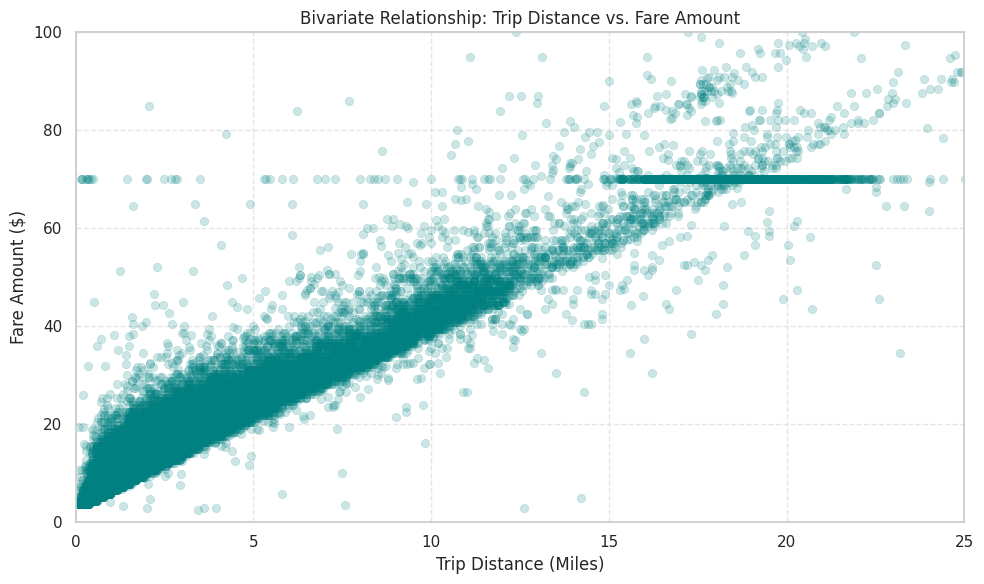

--- Scatterplot Insights ---
1. Strong Linear Trend: As distance increases, fare increases predictably.
2. Horizontal Lines: The solid horizontal bands (e.g., around $70) represent flat-rate airport trips, proving our earlier hypothesis test.


In [ ]:
# Sample 50,000 rows to prevent RAM crashes and visual overplotting
df_sample = df.sample(n=50000, random_state=42)

plt.figure(figsize=(10, 6))
# Using alpha=0.2 to show density where points overlap
sns.scatterplot(data=df_sample, x='trip_distance', y='fare_amount',
                alpha=0.2, edgecolor=None, color='teal')

plt.title("Bivariate Relationship: Trip Distance vs. Fare Amount")
plt.xlabel("Trip Distance (Miles)")
plt.ylabel("Fare Amount ($)")

# Zooming in to the most dense operational area for clarity
plt.xlim(0, 25)
plt.ylim(0, 100)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("--- Scatterplot Insights ---")
print("1. Strong Linear Trend: As distance increases, fare increases predictably.")
print("2. Horizontal Lines: The solid horizontal bands (e.g., around $70) represent flat-rate airport trips, proving our earlier hypothesis test.")

## 6. Spatial Exploration: Demand by Borough
Bar charts compare counts across categories.
We need to understand our spatial class imbalance. New York has five boroughs, but yellow taxis are legally and historically concentrated in specific administrative zones.

/tmp/ipykernel_1357/861201141.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=borough_counts, x='Borough', y='Trip_Count', palette='viridis')


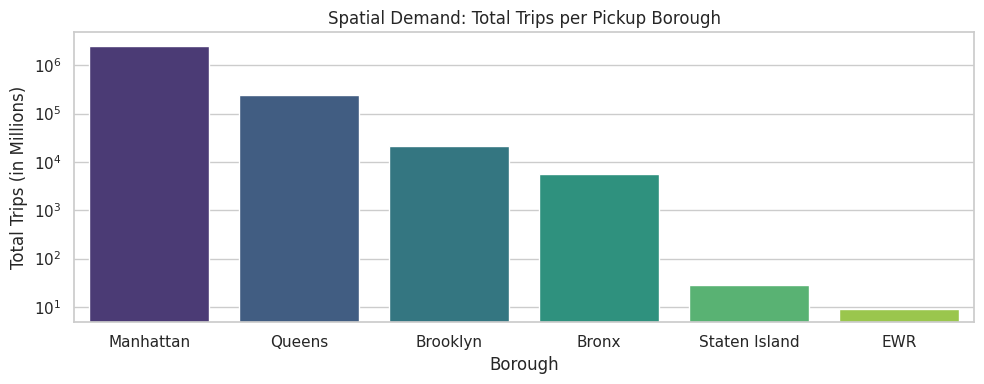

--- Spatial Insights ---
1. Manhattan dominates the dataset, accounting for the vast majority of pickups.
2. A Log-Scale was required to make the outer boroughs visible on the chart.
3. This extreme class imbalance means spatial clustering (K-Means) will be heavily weighted toward Manhattan coordinates.


In [ ]:
# Group by Pickup Borough and sort descending
borough_counts = df['PU_borough'].value_counts().reset_index()
borough_counts.columns = ['Borough', 'Trip_Count']

plt.figure(figsize=(10, 4))
sns.barplot(data=borough_counts, x='Borough', y='Trip_Count', palette='viridis')
plt.title("Spatial Demand: Total Trips per Pickup Borough")
plt.xlabel("Borough")
plt.ylabel("Total Trips (in Millions)")
plt.yscale('log') # Log scale because Manhattan dwarfs the others
plt.tight_layout()
plt.show()

print("--- Spatial Insights ---")
print(f"1. Manhattan dominates the dataset, accounting for the vast majority of pickups.")
print(f"2. A Log-Scale was required to make the outer boroughs visible on the chart.")
print("3. This extreme class imbalance means spatial clustering (K-Means) will be heavily weighted toward Manhattan coordinates.")